In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import RunResults, make_accuracy_scaling_plot

In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/main_text/figure_1'
SAVE_FIGURES = False
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS = RunResults(results_root=RESULTS_ROOT)

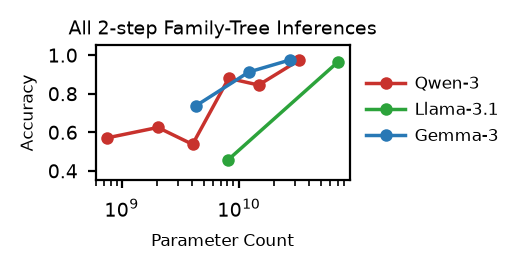

In [3]:
scaling_plot = make_accuracy_scaling_plot(
    RESULTS,
    prompt_preset='ABC_family_tree_yes_no',
    title='All 2-step Family-Tree Inferences',
)
if SAVE_FIGURES:
    scaling_plot.save(FIGURES_DIR / 'human_two_hop_accuracy.svg')

display(scaling_plot.fig)
plt.close(scaling_plot.fig)

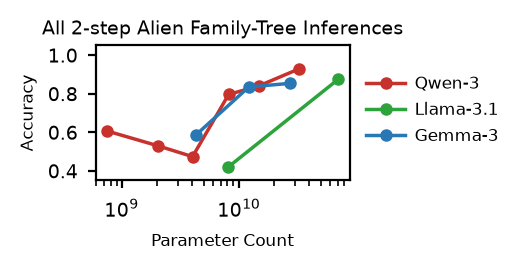

In [4]:
scaling_plot = make_accuracy_scaling_plot(
    RESULTS,
    prompt_preset='ABC_alien_family_tree_yes_no',
    title='All 2-step Alien Family-Tree Inferences',
)
if SAVE_FIGURES:
    scaling_plot.save(FIGURES_DIR / 'human_two_hop_accuracy.svg')

display(scaling_plot.fig)
plt.close(scaling_plot.fig)

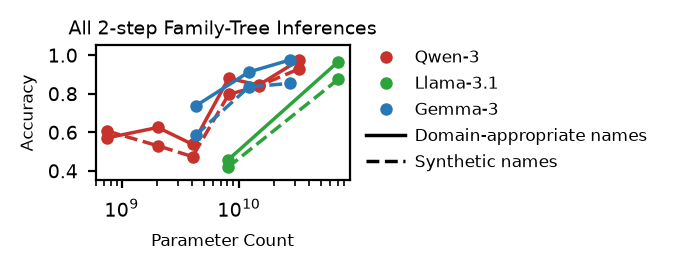

In [5]:
from matplotlib.lines import Line2D

HUMAN_ALPHA = 1.0
ALIEN_ALPHA = 1.0

combined_plot = make_accuracy_scaling_plot(
    RESULTS,
    prompt_preset='ABC_family_tree_yes_no',
    title='All 2-step Family-Tree Inferences',
    legend=False,
)
alien_plot = make_accuracy_scaling_plot(
    RESULTS,
    prompt_preset='ABC_alien_family_tree_yes_no',
    ax=combined_plot.ax,
    legend=False,
)

for line in combined_plot.artists['lines'].values():
    line.set_linestyle('-')
    line.set_alpha(HUMAN_ALPHA)
for line in alien_plot.artists['lines'].values():
    line.set_linestyle('--')
    line.set_alpha(ALIEN_ALPHA)

family_handles = [
    Line2D([], [], color=line.get_color(), marker='o', linestyle='None',
           markersize=4.5, markeredgewidth=0, label=line.get_label())
    for line in combined_plot.artists['lines'].values()
]
condition_handles = [
    Line2D([], [], color='black', linestyle='-', linewidth=1.25,
           alpha=HUMAN_ALPHA, label='Domain-appropriate names'),
    Line2D([], [], color='black', linestyle='--', linewidth=1.25,
           alpha=ALIEN_ALPHA, label='Synthetic names'),
]
combined_plot.artists['legend'] = combined_plot.ax.legend(
    handles=family_handles + condition_handles,
    loc='center left', bbox_to_anchor=(1.04, 0.52),
    frameon=False, fontsize=6, handlelength=2.3,
    handletextpad=0.6, borderaxespad=0, labelspacing=0.55,
)

if SAVE_FIGURES:
    combined_plot.save(FIGURES_DIR / 'human_alien_two_hop_accuracy.svg')

display(combined_plot.fig)
plt.close(combined_plot.fig)
